# Part I — Robustness of the Haslam gain and offset (survey subsets and more)

| | |
|---|---|
| **Reads** | `paper_outputs/pipeline/step5_fit/`, `paper_outputs/pipeline/step2_ring_tods/``beam_matched_tods.npz`, Part H's outputs, the TRIS rings |
| **Writes** | `paper_outputs/robustness_check/` (`robustness_table.csv`, figure) |
| **Feeds the paper** | main.tex:396 (and, by keyword only, 490, 507–508, 607) |

**Pipeline:** reads the pipeline's step 2 and step 5 products.

**Data sets:** step 5's data sets (`moonrunes.pipeline.fit_data_sets`: every map `sed.exclude_maps` leaves in with data on the ring, plus TRIS 600 and 820; 13 points with the current config). Where the text below names the six ring surveys, read these. The stored outputs are from the six-point set.

## Robustness check of the Haslam gain and offset

**Question (comment 2 on the TRIS paper).** Is the Haslam gain and offset correction robust across
subsets of the input maps and across spectral models?

**What is fitted.** Haslam = g P + z over the ring samples (York, errors on both axes, σ inflated by √(χ²/ν) when > 1, as
Plot 3 and the paper's Figure 9). P is the spectral fit's A at the 408 MHz pivot, as in Figure 9's (c).
Haslam is always the target, never an input. The data, the errors and the functions (`york`, `york_cov`, `inner_fit`
with the log-frequencies passed in, `tris_only_p408`, `haslam_fit`) are those of `10_paper_plots` cell 22 (Figure 9). The only
change: `haslam_fit` takes the Haslam samples as arguments so that a subset of the ring can be fitted. Errors are as
now (zero-level terms inside the per-point errors, no offsets fitted).

**Baseline** (the reference for every difference): the power law on step 5's data sets, Cygnus A mask RA 299.9 ± 25° (103 of 120
samples). It should give g = 1.0548 ± 0.0536, z = −4.77 ± 1.47 K.

**The grid (fixed; nothing added).**
1. Survey subsets: all; each one left out; the LWA1 maps left out; Maipu 45 + TRIS 600 + TRIS 820 (power law only); the six-survey subset (TRIS 600, 820, LWA1 35, Maipu 45, LWA1 80, Stockert 1420; checked against the paper's g and z);
   TRIS only, the two-point power law of Plot 3 (power law only; reference row).
2. Spectral models: power law for every subset; curved power law for subsets with at least four surveys.
3. Sample subsets (all data sets, both models): Cygnus A mask ±15° and ±35°; the two halves of the ±25° unmasked ring
   split at RA = 200°.
4. Zero-level treatment: three rows copied from Part H's Table 3(a), not refitted.

Differences are fit − baseline, in g units or K. "Inside baseline error bars" = |g − g_baseline| < σ_g(baseline) and
|z − z_baseline| < σ_z(baseline).

Output: `paper_outputs/robustness_check/` — `robustness_table.csv`, `robustness_gz_plane.png` / `.pdf`.

### 1. Data, errors and the fitting functions

In [1]:
%matplotlib inline
import time as _nb_time; _NB_T0 = _nb_time.time()   # notebook run time, printed by the last cell
import os
os.environ.setdefault("TQDM_DISABLE", "1")
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "run_pipeline.yaml").exists())
sys.path.insert(0, str(REPO / "src"))
warnings.filterwarnings("ignore")
from moonrunes.config import load_config
from moonrunes import sed_prototype as sp
from moonrunes.sed_prototype import PUBLISHED_ERRORS, ring_sigma, sigma_for
from moonrunes.style import use_tris_style, COLORS
use_tris_style()

config = load_config(REPO / "configs" / "run_pipeline.yaml")
OUT = REPO / "paper_outputs" / "robustness_check"
OUT.mkdir(parents=True, exist_ok=True)
ZL_DIR = REPO / "paper_outputs" / "zero_level_offsets"            # Part H, read only

def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(OUT / f"{name}.{ext}")

print("ERRORS AS NOW: every per-point error includes its zero-level term (ring_sigma for TRIS, sigma_for for the "
      "surveys and Haslam);\nno zero-level offsets are fitted (except in the copied notebook 20 rows, which say so).  "
      "Haslam is the target, never an input.\nDifferences are fit − baseline, in K or in g units.\n")

# ---- data and errors, as Figure 9 (10_paper_plots cell 22) ----
SRC = REPO / "paper_outputs" / "pipeline" / "step5_fit"                       # run_pipeline.py step 5: TRIS ring data and the fits
BM = REPO / "paper_outputs" / "pipeline" / "step2_ring_tods" / "beam_matched_tods.npz"     # run_pipeline.py step 2
HASLAM = "HASLAM_DESTRIPED_ONLY.fits"
from moonrunes.pipeline import fit_data_sets
SURVEYS = fit_data_sets()           # step 5's data sets (TRIS included), low frequency first: key -> label
SIX_NB08 = ["LWA_35MHz.fits", "MAIPU_45mhZ.fits", "LWA_80MHz.fits", "TRIS_600", "TRIS_820",
            "STOCKERT_VILLA_1400MHZ.fits"]   # the six-survey subset: the reproduction check below
KEYS = list(SURVEYS)
NOT_TRIS = [k for k in KEYS if not k.startswith("TRIS_")]
NU0 = 408.0
CYG_RA, CYG_HALF = 299.9, 25.0      # the baseline mask
RA_SPLIT = 200.0                    # the two halves of the ring
INFLATE = True                      # york(): scale σ by sqrt(χ²/ν) when χ²/ν > 1 (Part E's rule)

RA = np.load(SRC / "ring_ra.npy")
N = RA.size
T = {k: np.full(N, np.nan) for k in KEYS}
S_CACHE = {k: np.full(N, np.nan) for k in KEYS}
FREQ = {}
for u in range(N):
    r = np.load(SRC / "fits" / f"unit{u:03d}__power_law.npz", allow_pickle=False)
    for k, nu, t, s in zip((str(x) for x in r["keys"]), r["nu"], r["t"], r["s"]):
        T[k][u], S_CACHE[k][u], FREQ[k] = t, s, float(nu)
zb = np.load(BM, allow_pickle=False)
assert np.allclose(zb["ra_deg"], RA)
for k in NOT_TRIS:
    T[k] = np.asarray(zb[f"survey::{k}"], dtype=float)
TH_ALL = np.asarray(zb[f"survey::{HASLAM}"], dtype=float)

tris_mod = sp.import_limtod_tris(config)
archive = config.resolve_path("paths.tris_archive_dir")
S, RINGS = {}, {}
for k in KEYS:
    if k.startswith("TRIS_"):
        RINGS[k] = tris_mod.read_tris_ring(archive / f"TRIS_absolute_{k[5:]}.txt")
        assert np.allclose(np.asarray(RINGS[k].ra_deg), RA)
        S[k] = ring_sigma(RINGS[k])
        assert np.allclose(S[k], S_CACHE[k]), k
    else:
        S[k] = np.asarray(sigma_for(dict(freq_mhz=FREQ[k], file=k), T[k]), dtype=float)
SH_ALL = np.asarray(sigma_for(dict(freq_mhz=NU0, file=HASLAM), TH_ALL), dtype=float)

# every finite sample; the sample sets below are index sets into these
FINITE = np.all([np.isfinite(T[k]) for k in KEYS], axis=0) & np.isfinite(TH_ALL)
NU = np.array([FREQ[k] for k in KEYS])
X = np.log(NU / NU0)
TD = np.stack([T[k] for k in KEYS], axis=1)          # (120, number of surveys); fits at every finite sample
SD = np.stack([S[k] for k in KEYS], axis=1)

def cyg_keep(half):
    d = np.abs((RA - CYG_RA + 180.0) % 360.0 - 180.0)
    return FINITE & (d > half)

SAMPLE_SETS = {f"Cygnus A mask ±{CYG_HALF:g}° (baseline)": cyg_keep(CYG_HALF),
               "Cygnus A mask ±15°": cyg_keep(15.0),
               "Cygnus A mask ±35°": cyg_keep(35.0),
               f"±{CYG_HALF:g}° mask, RA < {RA_SPLIT:g}°": cyg_keep(CYG_HALF) & (RA < RA_SPLIT),
               f"±{CYG_HALF:g}° mask, RA ≥ {RA_SPLIT:g}°": cyg_keep(CYG_HALF) & (RA >= RA_SPLIT)}
BASE_SET = f"Cygnus A mask ±{CYG_HALF:g}° (baseline)"
print(f"{FINITE.sum()} of {N} ring samples finite in all six surveys and Haslam")
for name, keep in SAMPLE_SETS.items():
    print(f"  {name}: {keep.sum()} samples")
print("frequencies [MHz]: " + ", ".join(f"{SURVEYS[k]} {FREQ[k]:g}" for k in KEYS))


# ---- the fitting functions, as 10_paper_plots cell 22 (without its ANC_ prefix) ----
def york(x, y, sx, sy, n_iter=200, tol=1e-12):
    # y = a x + b with errors on both axes (York et al. 2004, Am. J. Phys. 72, 367; no x-y correlation).
    vx, vy = np.asarray(sx, float) ** 2, np.asarray(sy, float) ** 2
    a = np.polyfit(x, y, 1)[0]
    for _ in range(n_iter):
        W = 1.0 / (vy + a * a * vx)
        xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
        U, V = x - xb, y - yb
        bet = W * (U * vy + a * V * vx)
        a_new = np.sum(W * bet * V) / np.sum(W * bet * U)
        done = abs(a_new - a) <= tol * abs(a_new)
        a = a_new
        if done:
            break
    W = 1.0 / (vy + a * a * vx)
    xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
    b = yb - a * xb
    xa = xb + W * ((x - xb) * vy + a * (y - yb) * vx)          # adjusted x values
    xab = np.sum(W * xa) / W.sum()
    sa = np.sqrt(1.0 / np.sum(W * (xa - xab) ** 2))
    sb = np.sqrt(1.0 / W.sum() + xab ** 2 * sa ** 2)
    chi2 = float(np.sum(W * (y - a * x - b) ** 2))
    dof = x.size - 2
    f = np.sqrt(max(1.0, chi2 / dof)) if INFLATE else 1.0
    return dict(a=a, sa=sa * f, b=b, sb=sb * f, chi2_dof=chi2 / dof)

def york_cov(x, y, sx, sy, fit):
    # cov(a, b) of the York fit above (York et al. 2004: -x̄_adj σ_a²), with the same √(χ²/ν) inflation.
    vx, vy, a = np.asarray(sx, float) ** 2, np.asarray(sy, float) ** 2, fit["a"]
    W = 1.0 / (vy + a * a * vx)
    xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
    xa = xb + W * ((x - xb) * vy + a * (y - yb) * vx)
    xab = np.sum(W * xa) / W.sum()
    return -xab * fit["sa"] ** 2

def inner_fit(t, s, npar, x, p0=None, n_iter=500, tol=1e-11):
    """Minimum chi^2 of T = exp(lnA + beta x [+ C x^2]) at every sample (rows of t, s).  Returns p, chi2, cov.
    Part H's inner_fit, with the log-frequencies x passed in so that a subset of the surveys can be fitted."""
    w = 1.0 / s ** 2
    V = np.stack([np.ones_like(x), x, x ** 2][:npar], axis=1)            # (npts, npar)
    if p0 is None or not np.all(np.isfinite(p0)):      # weighted straight line in log T
        lt = np.log(np.clip(t, 1e-300, None)); wl = (np.clip(t, 1e-300, None) / s) ** 2
        p = np.linalg.solve(np.einsum("ni,sn,nj->sij", V, wl, V), np.einsum("ni,sn,sn->si", V, wl, lt)[..., None])[..., 0]
    else:
        p = p0.copy()
    def chi2_of(p):
        m = np.exp(p @ V.T)
        return np.sum(w * (t - m) ** 2, axis=1), m
    c, m = chi2_of(p)
    lam = np.full(t.shape[0], 1e-3)
    eye = np.eye(npar)
    for _ in range(n_iter):
        J = m[:, :, None] * V[None]
        JTJ = np.einsum("sni,sn,snj->sij", J, w, J)
        g = np.einsum("sni,sn,sn->si", J, w, t - m)
        d = np.linalg.solve(JTJ + lam[:, None, None] * JTJ * eye, g[..., None])[..., 0]
        cn, mn = chi2_of(p + d)
        better = cn <= c
        p[better] += d[better]; m[better] = mn[better]
        dc = np.where(better, c - cn, 0.0); c = np.where(better, cn, c)
        lam = np.where(better, lam * 0.3, lam * 10.0).clip(1e-12, 1e12)
        if np.all((np.abs(d).max(axis=1) < tol) | (better & (dc < 1e-13 * np.maximum(c, 1.0)))):
            break
    J = m[:, :, None] * V[None]
    cov = np.linalg.pinv(np.einsum("sni,sn,snj->sij", J, w, J))
    return p, c, cov

I6, I8 = KEYS.index("TRIS_600"), KEYS.index("TRIS_820")
L68 = np.log(NU[I8] / NU[I6]); L48 = np.log(NU0 / NU[I6])
def tris_only_p408(t6, t8, s6, s8):
    """P(408) from the power law through the two TRIS points, and its 1 sigma (notebook 20)."""
    beta = np.log(t8 / t6) / L68
    P = t6 * np.exp(beta * L48)
    c6, c8 = 1 - L48 / L68, L48 / L68                 # ln P = c6 ln t6 + c8 ln t8
    return P, P * np.hypot(c6 * s6 / t6, c8 * s8 / t8)

def haslam_fit(P, SP, H_T, H_S):
    """Haslam = g P + z (York), with the Haslam samples passed in so that a sample subset can be fitted."""
    f = york(P, H_T, SP, H_S)
    cgz = york_cov(P, H_T, SP, H_S, f)
    return dict(g=f["a"], sg=f["sa"], z=f["b"], sz=f["sb"], chi2_dof=f["chi2_dof"],
                C=np.array([[f["sa"] ** 2, cgz], [cgz, f["sb"] ** 2]]))

ERRORS AS NOW: every per-point error includes its zero-level term (ring_sigma for TRIS, sigma_for for the surveys and Haslam);
no zero-level offsets are fitted (except in the copied notebook 20 rows, which say so).  Haslam is the target, never an input.
Differences are fit − baseline, in K or in g units.

120 of 120 ring samples finite in all six surveys and Haslam
  Cygnus A mask ±25° (baseline): 103 samples
  Cygnus A mask ±15°: 110 samples
  Cygnus A mask ±35°: 97 samples
  ±25° mask, RA < 200°: 67 samples
  ±25° mask, RA ≥ 200°: 36 samples
frequencies [MHz]: LWA1 35 35, LWA1 38 38, LWA1 40 40, LWA1 45 45, Maipu 45 45, LWA1 50 50, LWA1 60 60, LWA1 70 70, LWA1 74 74, LWA1 80 80, TRIS 600 600.5, TRIS 820 817.8, Stockert 1420 1420


### 2. The grid fits

Each spectral fit is made once per survey subset and model at every finite ring sample; the Haslam fit then uses the
samples of its sample set. `inner_fit` does not report convergence, so the cell checks it from outside: a sample is
flagged if its fit is not finite, or if restarting `inner_fit` from its own solution moves a parameter by more than
1e-6 or lowers χ² by more than 1e-6 χ². Non-finite samples are left out of that Haslam fit; flagged but finite samples are
kept as fitted. Both are counted in the convergence table.

In [2]:
# The grid: Haslam = g P + z, with P = A at the 408 MHz pivot of a spectral fit to a subset of the surveys.
MODEL_NPAR = {"power law": 2, "curved power law": 3}
OK = np.flatnonzero(FINITE)
NONCONV_TOL = 1e-6

def spectral_p408(cols, npar):
    """A(408) and its 1σ at every finite sample from inner_fit on the surveys in cols.  Convergence check, outside
    inner_fit: a sample is flagged if its fit is not finite (or has no positive variance of ln A), or if restarting
    inner_fit from its own solution moves any parameter by more than 1e-6 or lowers χ² by more than 1e-6 χ²."""
    t, s, x = TD[OK][:, cols], SD[OK][:, cols], X[cols]
    p, c, cov = inner_fit(t, s, npar, x)
    p2, c2, _ = inner_fit(t, s, npar, x, p0=p)
    var = cov[:, 0, 0]
    finite = np.all(np.isfinite(p), axis=1) & np.isfinite(c) & np.isfinite(var) & (var > 0)
    moved = (np.nan_to_num(np.abs(p2 - p), nan=np.inf).max(axis=1) > NONCONV_TOL) | (c - c2 > NONCONV_TOL * np.maximum(c, 1.0))
    A, sA = np.full(N, np.nan), np.full(N, np.nan)
    A[OK] = np.exp(p[:, 0]); sA[OK] = A[OK] * np.sqrt(np.where(var > 0, var, np.nan))
    bad_finite, bad_moved = np.zeros(N, bool), np.zeros(N, bool)
    bad_finite[OK] = ~finite; bad_moved[OK] = finite & moved
    return A, sA, bad_finite, bad_moved

ROWS, CONV = [], []
def add(group, subset, model, n_surveys, P, SP, keep, bad_finite=None, bad_moved=None):
    """One Haslam fit over the samples in keep.  Samples whose spectral fit is not finite are left out of the York fit
    (and counted); samples flagged as not converged but finite are kept with the value inner_fit returned (and counted)."""
    use = keep.copy()
    if bad_finite is not None:
        use &= ~bad_finite
        CONV.append({"group": group, "subset": subset, "model": model, "samples in set": int(keep.sum()),
                     "not finite (left out)": int((keep & bad_finite).sum()),
                     "not converged, finite (kept)": int((keep & bad_moved).sum())})
    f = haslam_fit(P[use], SP[use], TH_ALL[use], SH_ALL[use])
    ROWS.append({"group": group, "subset": subset, "model": model, "number of surveys": n_surveys,
                 "number of samples": int(use.sum()), "g": f["g"], "sigma_g": f["sg"], "z [K]": f["z"],
                 "sigma_z [K]": f["sz"]})

SUBSETS = {"all": KEYS}
for k in KEYS:
    SUBSETS[f"without {SURVEYS[k]}"] = [q for q in KEYS if q != k]
SUBSETS["without the LWA1 maps"] = ["MAIPU_45mhZ.fits", "TRIS_600", "TRIS_820", "STOCKERT_VILLA_1400MHZ.fits"]
SUBSETS["best-measured three (Maipu 45, TRIS 600, TRIS 820)"] = ["MAIPU_45mhZ.fits", "TRIS_600", "TRIS_820"]
SUBSETS["the six ring surveys (notebook 08)"] = SIX_NB08

FITS = {}
base_keep = SAMPLE_SETS[BASE_SET]
for name, keys in SUBSETS.items():
    cols = [KEYS.index(k) for k in keys]
    for model, npar in MODEL_NPAR.items():
        if model == "curved power law" and len(keys) < 4:
            continue
        FITS[name, model] = spectral_p408(cols, npar)
        add("survey subsets", name + (" (baseline)" if (name, model) == ("all", "power law") else ""), model,
            len(keys), *FITS[name, model][:2], base_keep, *FITS[name, model][2:])
P_T, SP_T = tris_only_p408(TD[:, I6], TD[:, I8], SD[:, I6], SD[:, I8])
add("survey subsets", "TRIS only (two-point power law, as Plot 3)", "power law", 2, P_T, SP_T, base_keep & np.isfinite(P_T))

for name, keep in SAMPLE_SETS.items():
    if name == BASE_SET:
        continue
    for model in MODEL_NPAR:
        add("sample subsets", name, model, len(KEYS), *FITS["all", model][:2], keep, *FITS["all", model][2:])

BASE = ROWS[0]
print(f"baseline ({len(KEYS)}-survey power law, {BASE['number of samples']} samples): g = {BASE['g']:.4f} ± {BASE['sigma_g']:.4f}, "
      f"z = {BASE['z [K]']:.2f} ± {BASE['sigma_z [K]']:.2f} K")
expected = dict(g=1.0548, sg=0.0536, z=-4.77, sz=1.47)
SIX = next(r for r in ROWS if r["subset"] == "the six ring surveys (notebook 08)" and r["model"] == "power law")
same = (round(SIX["g"], 4) == expected["g"] and round(SIX["sigma_g"], 4) == expected["sg"]
        and round(SIX["z [K]"], 2) == expected["z"] and round(SIX["sigma_z [K]"], 2) == expected["sz"])
print("the six ring surveys against notebook 08 Figures 15-16, Part 1(c), g = 1.0548 ± 0.0536, z = -4.77 ± 1.47 K -> "
      + ("REPRODUCED" if same else "NOT REPRODUCED"))
assert same and SIX["number of samples"] == 103

conv = pd.DataFrame(CONV)
print("\nconvergence of the spectral fits, per Haslam fit (samples in its sample set)\n")
with pd.option_context("display.width", 250, "display.max_columns", 20):
    print(conv.to_string(index=False))

baseline (13-survey power law, 103 samples): g = 1.0553 ± 0.0537, z = -4.80 ± 1.47 K
the six ring surveys against notebook 08 Figures 15-16, Part 1(c), g = 1.0548 ± 0.0536, z = -4.77 ± 1.47 K -> REPRODUCED

convergence of the spectral fits, per Haslam fit (samples in its sample set)

         group                                             subset            model  samples in set  not finite (left out)  not converged, finite (kept)
survey subsets                                     all (baseline)        power law             103                      0                             0
survey subsets                                                all curved power law             103                      0                             0
survey subsets                                    without LWA1 35        power law             103                      0                             0
survey subsets                                    without LWA1 35 curved power law             103         

### 3. Zero-level treatment: rows copied from Part H

Part H's cache (`paper_outputs/zero_level_offsets/cache/results.npz`) stores the fitted offsets of each
configuration, not the Table 3(a) rows. The rows are copied from Part H's saved `table3a_haslam_gain_offset.csv`
and checked against the same rows rebuilt from the cached offsets. These rows use Part H's treatment: the
zero-level terms are removed from the errors and the offsets are fitted, except the curved baseline row, which has errors
as now.

In [3]:
# Zero-level treatment: three rows of Part H's Table 3(a), copied, not refitted.
# Part H's results.npz holds the MAP offsets of each configuration, not the Table 3(a) rows; the rows are copied
# from Part H's saved table3a_haslam_gain_offset.csv, and checked against the rows rebuilt from the cached
# offsets (data − offsets, errors without the zero-level terms, as Part H does).
ZL_ROWS = {"all-survey power law A(408), (1)": ("power law", "offsets fitted, notebook 20 configuration (1)"),
           "all-survey curved PL A(408), (3)": ("curved power law", "offsets fitted, notebook 20 configuration (3)"),
           "all-survey curved PL A(408), baseline": ("curved power law", "no offsets, errors as now (notebook 20 baseline)")}
CFG = {"all-survey power law A(408), (1)": ("(1) power law, offsets on all", 2),
       "all-survey curved PL A(408), (3)": ("(3) curved power law, offsets on all", 3),
       "all-survey curved PL A(408), baseline": ("baseline curved power law, errors as now", 3)}
t3a = pd.read_csv(ZL_DIR / "table3a_haslam_gain_offset.csv").set_index("prediction P")
res = json.loads(str(np.load(ZL_DIR / "cache" / "results.npz", allow_pickle=False)["blob"]))

# Part H's offset priors: TRIS II Table 3 (= the zero-level term inside ring_sigma), the published zero_k otherwise
PRIOR, S_NOZL = {}, {}
for k in KEYS:
    if k.startswith("TRIS_"):
        z = RINGS[k].zero_level_uncertainty_k
        PRIOR[k] = float(z) if np.isscalar(z) else max(z.positive_k, z.negative_k)
        stat = np.asarray(RINGS[k].statistical_uncertainty_k, dtype=float)
        S_NOZL[k] = np.where(stat > 0, stat, stat[stat > 0].min())
    else:
        e = PUBLISHED_ERRORS[k]
        if e["zero_k"] > 0:
            PRIOR[k] = e["zero_k"]
        S_NOZL[k] = np.hypot(e["scale"] * T[k], e["noise_k"])
assert np.isclose(PRIOR["TRIS_600"], 0.066) and np.isclose(PRIOR["TRIS_820"], 0.430)
OFF_ALL = [k for k in KEYS if k in PRIOR]
ib = np.flatnonzero(base_keep)

print("notebook 20 Table 3(a) rows: copied value vs rebuilt from the cached offsets (rebuilt − copied)")
for lab, (model, subset) in ZL_ROWS.items():
    r = t3a.loc[lab]
    cfg, npar = CFG[lab]
    u = np.asarray(res[cfg]["u"])
    o = np.zeros(len(KEYS))
    if u.size:
        o[[KEYS.index(k) for k in OFF_ALL]] = u * np.array([PRIOR[k] for k in OFF_ALL])
        s = np.stack([S_NOZL[k][ib] if k in OFF_ALL else S[k][ib] for k in KEYS], axis=1)
    else:
        s = SD[ib]
    p, _, cov = inner_fit(TD[ib] - o, s, npar, X)
    A = np.exp(p[:, 0])
    f = haslam_fit(A, A * np.sqrt(cov[:, 0, 0]), TH_ALL[ib], SH_ALL[ib])
    d = np.array([f["g"] - r["g"], f["sg"] - r["σ_g"], f["z"] - r["z [K]"], f["sz"] - r["σ_z [K]"]])
    print(f"  {lab}: Δg {d[0]:+.1e}, Δσ_g {d[1]:+.1e}, Δz {d[2]:+.1e} K, Δσ_z {d[3]:+.1e} K -> "
          + ("same" if np.all(np.abs(d) < 1e-6) else "DIFFERENT"))
    assert np.all(np.abs(d) < 1e-6), lab
    ROWS.append({"group": "zero-level treatment (notebook 20)", "subset": subset, "model": model, "number of surveys": len(KEYS),
                 "number of samples": len(ib), "g": r["g"], "sigma_g": r["σ_g"], "z [K]": r["z [K]"],
                 "sigma_z [K]": r["σ_z [K]"]})
# Part H's curved baseline is this Part's all-survey curved fit
cv = next(x for x in ROWS if x["subset"] == "all" and x["model"] == "curved power law")
print(f"  notebook 20 curved baseline − this Part's all-survey curved fit: Δg {t3a.loc['all-survey curved PL A(408), baseline', 'g'] - cv['g']:+.1e}, "
      f"Δz {t3a.loc['all-survey curved PL A(408), baseline', 'z [K]'] - cv['z [K]']:+.1e} K")

notebook 20 Table 3(a) rows: copied value vs rebuilt from the cached offsets (rebuilt − copied)
  all-survey power law A(408), (1): Δg +0.0e+00, Δσ_g +4.9e-17, Δz +0.0e+00 K, Δσ_z +0.0e+00 K -> same
  all-survey curved PL A(408), (3): Δg +0.0e+00, Δσ_g +8.3e-17, Δz +0.0e+00 K, Δσ_z +0.0e+00 K -> same
  all-survey curved PL A(408), baseline: Δg -8.3e-11, Δσ_g -5.7e-12, Δz +3.3e-09 K, Δσ_z -2.2e-10 K -> same
  notebook 20 curved baseline − this Part's all-survey curved fit: Δg +8.3e-11, Δz -3.3e-09 K


### 4. The table

In [4]:
# The table: every fit against the baseline, by subtraction.
tab = pd.DataFrame(ROWS)
tab["g - g_baseline"] = tab["g"] - BASE["g"]
tab["z - z_baseline [K]"] = tab["z [K]"] - BASE["z [K]"]
IN_G = np.abs(tab["g - g_baseline"]) < BASE["sigma_g"]
IN_Z = np.abs(tab["z - z_baseline [K]"]) < BASE["sigma_z [K]"]
tab["inside baseline error bars"] = np.where(IN_G & IN_Z, "yes", "no")
tab.to_csv(OUT / "robustness_table.csv", index=False)
with pd.option_context("display.width", 300, "display.max_columns", 20, "display.max_colwidth", 60):
    print(f"Haslam = g P + z; baseline g = {BASE['g']:.4f} ± {BASE['sigma_g']:.4f}, z = {BASE['z [K]']:.2f} ± "
          f"{BASE['sigma_z [K]']:.2f} K\n")
    print(tab.round(4).to_string(index=False))

others = tab.index[1:]                           # every fit except the baseline itself
print(f"\n{len(others)} fits besides the baseline: inside the baseline σ_g in g: {int(IN_G[others].sum())}; inside the "
      f"baseline σ_z in z: {int(IN_Z[others].sum())}; inside both: {int((IN_G & IN_Z)[others].sum())}")
out = tab.loc[others][~(IN_G & IN_Z)[others]]
print("\noutside the baseline error bars (baseline σ_g = %.4f, σ_z = %.2f K):" % (BASE["sigma_g"], BASE["sigma_z [K]"]))
for _, r in out.iterrows():
    print(f"  {r['subset']}, {r['model']}: g − g_baseline = {r['g - g_baseline']:+.4f}"
          + ("" if abs(r['g - g_baseline']) < BASE['sigma_g'] else " (outside)")
          + f", z − z_baseline = {r['z - z_baseline [K]']:+.2f} K"
          + ("" if abs(r['z - z_baseline [K]']) < BASE['sigma_z [K]'] else " (outside)"))

# curved − power law for the same subset (same samples)
rows = []
pairs = tab[tab["group"] != "zero-level treatment (notebook 20)"].assign(pair=lambda d: d["subset"].str.replace(" (baseline)", "", regex=False))
for (grp, sub), d in pairs.groupby(["group", "pair"], sort=False):
    if set(d["model"]) == set(MODEL_NPAR):
        pl, cv = d[d["model"] == "power law"].iloc[0], d[d["model"] == "curved power law"].iloc[0]
        dg, dz = cv["g"] - pl["g"], cv["z [K]"] - pl["z [K]"]
        rows.append({"group": grp, "subset": sub, "g curved − g power law": dg,
                     "z curved − z power law [K]": dz,
                     "|Δg| > baseline σ_g": "yes" if abs(dg) > BASE["sigma_g"] else "no",
                     "|Δz| > baseline σ_z": "yes" if abs(dz) > BASE["sigma_z [K]"] else "no"})
tab_cp = pd.DataFrame(rows)
print("\ncurved power law − power law, same survey subset and samples\n")
with pd.option_context("display.width", 300, "display.max_columns", 20):
    print(tab_cp.round(4).to_string(index=False))

Haslam = g P + z; baseline g = 1.0553 ± 0.0537, z = -4.80 ± 1.47 K

                             group                                             subset            model  number of surveys  number of samples      g  sigma_g   z [K]  sigma_z [K]  g - g_baseline  z - z_baseline [K] inside baseline error bars
                    survey subsets                                     all (baseline)        power law                 13                103 1.0553   0.0537 -4.8024       1.4672          0.0000              0.0000                        yes
                    survey subsets                                                all curved power law                 13                103 0.9938   0.0550 -6.2102       1.6766         -0.0615             -1.4078                         no
                    survey subsets                                    without LWA1 35        power law                 12                103 1.0550   0.0536 -4.7947       1.4669         -0.0002              0.

### 5. Figure — the g–z plane

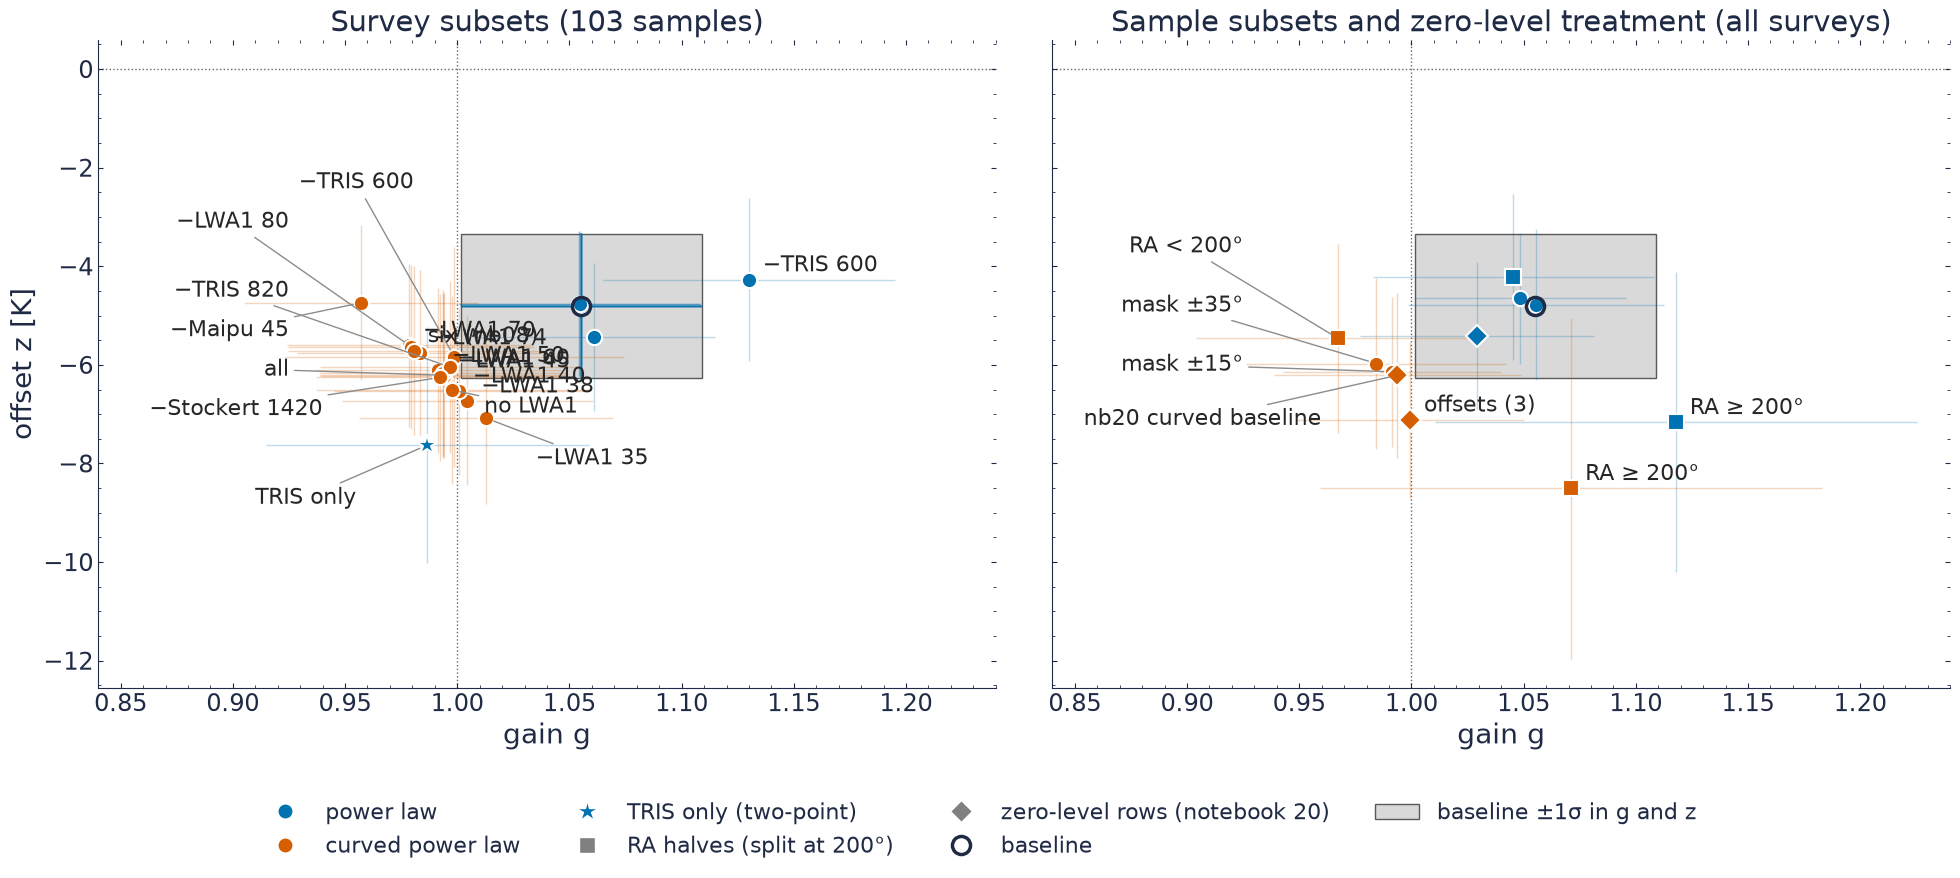

saved robustness_gz_plane.png / .pdf in paper_outputs/robustness_check


In [5]:
# Figure: the g-z plane.  Left: survey subsets; right: mask, RA halves and zero-level treatment.
COL = {"power law": "#0072B2", "curved power law": "#D55E00"}
SHORT = {"all (baseline)": "baseline", "all": "all",
         "without the LWA1 maps": "no LWA1", "the six ring surveys (notebook 08)": "six (nb08)", "best-measured three (Maipu 45, TRIS 600, TRIS 820)": "best 3",
         "TRIS only (two-point power law, as Plot 3)": "TRIS only",
         "Cygnus A mask ±15°": "mask ±15°", "Cygnus A mask ±35°": "mask ±35°",
         f"±{CYG_HALF:g}° mask, RA < {RA_SPLIT:g}°": f"RA < {RA_SPLIT:g}°",
         f"±{CYG_HALF:g}° mask, RA ≥ {RA_SPLIT:g}°": f"RA ≥ {RA_SPLIT:g}°",
         "offsets fitted, notebook 20 configuration (1)": "offsets (1)",
         "offsets fitted, notebook 20 configuration (3)": "offsets (3)",
         "no offsets, errors as now (notebook 20 baseline)": "nb20 curved baseline"}
SHORT.update({f"without {v}": f"−{v}" for v in SURVEYS.values()})
MARK = {"survey subsets": "o", "Cygnus A mask": "o", "RA half": "s", "zero-level treatment (notebook 20)": "D"}

def marker(r):
    if r["subset"].startswith("TRIS only"):
        return "*"
    if r["group"] == "sample subsets":
        return "o" if r["subset"].startswith("Cygnus") else "s"
    return MARK[r["group"]]

CV, PL = "curved power law", "power law"
LABEL_POS = {   # (g, z [K], alignment) of the labels in the crowded parts of the panels, joined to their points
    ("without LWA1 80", CV): (0.925, -3.1, "right"), ("without TRIS 600", CV): (0.955, -2.3, "center"),
    ("without TRIS 820", CV): (0.925, -4.5, "right"), ("without Maipu 45", CV): (0.925, -5.3, "right"),
    ("all", CV): (0.925, -6.1, "right"), ("without Stockert 1420", CV): (0.94, -6.9, "right"),
    ("TRIS only (two-point power law, as Plot 3)", PL): (0.955, -8.7, "right"),
    ("without the LWA1 maps", CV): (1.012, -6.85, "left"), ("without LWA1 35", CV): (1.035, -7.9, "left"),
    (f"±{CYG_HALF:g}° mask, RA < {RA_SPLIT:g}°", CV): (0.925, -3.6, "right"),
    ("Cygnus A mask ±35°", CV): (0.925, -4.8, "right"), ("Cygnus A mask ±15°", CV): (0.925, -6.0, "right"),
    ("no offsets, errors as now (notebook 20 baseline)", CV): (0.96, -7.1, "right")}

def panel(ax, d, title):
    g0, sg0, z0, sz0 = BASE["g"], BASE["sigma_g"], BASE["z [K]"], BASE["sigma_z [K]"]
    ax.add_patch(Rectangle((g0 - sg0, z0 - sz0), 2 * sg0, 2 * sz0, fc="0.85", ec="0.35", zorder=0))
    ax.axvline(1, color="0.4", ls=":", zorder=1)
    ax.axhline(0, color="0.4", ls=":", zorder=1)
    for i, r in d.iterrows():
        c = COL[r["model"]]
        ax.errorbar(r["g"], r["z [K]"], xerr=r["sigma_g"], yerr=r["sigma_z [K]"], fmt="none", ecolor=c, alpha=0.25,
                    zorder=2)
        ax.plot(r["g"], r["z [K]"], marker(r), ms=16 if marker(r) == "*" else 11, mfc=c, mec="white", mew=1.5, zorder=4)
        if r["inside baseline error bars"] == "no":
            lab = SHORT.get(r["subset"], r["subset"])
            pos = LABEL_POS.get((r["subset"], r["model"]))
            if pos is None:
                ax.annotate(lab, (r["g"], r["z [K]"]), xytext=(10, 6), textcoords="offset points", fontsize=16,
                            color="0.15", zorder=5)
            else:
                ax.annotate(lab, (r["g"], r["z [K]"]), xytext=pos[:2], textcoords="data", ha=pos[2], va="center",
                            fontsize=16, color="0.15", zorder=5,
                            arrowprops=dict(arrowstyle="-", color="0.55", shrinkA=2, shrinkB=6))
    ax.plot(BASE["g"], BASE["z [K]"], "o", ms=13, mfc="none", mec=COLORS["ink"], mew=2.5, zorder=5)
    ax.set_xlabel("gain g")
    ax.set_title(title)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

with plt.rc_context({"font.size": 20, "axes.titlesize": 21, "axes.labelsize": 20, "xtick.labelsize": 17,
                     "ytick.labelsize": 17, "legend.fontsize": 16}):
    fig, axes = plt.subplots(1, 2, figsize=(20, 9), sharex=True, sharey=True)
    panel(axes[0], tab[tab["group"] == "survey subsets"], "Survey subsets (103 samples)")
    panel(axes[1], tab[tab["group"] != "survey subsets"], "Sample subsets and zero-level treatment (all surveys)")
    axes[0].set_ylabel("offset z [K]")
    axes[0].set_xlim(0.84, 1.24)
    from matplotlib.lines import Line2D
    h = [Line2D([], [], ls="", marker="o", ms=11, mfc=COL["power law"], mec="white", label="power law"),
         Line2D([], [], ls="", marker="o", ms=11, mfc=COL["curved power law"], mec="white", label="curved power law"),
         Line2D([], [], ls="", marker="*", ms=16, mfc=COL["power law"], mec="white", label="TRIS only (two-point)"),
         Line2D([], [], ls="", marker="s", ms=11, mfc="0.5", mec="white", label=f"RA halves (split at {RA_SPLIT:g}°)"),
         Line2D([], [], ls="", marker="D", ms=11, mfc="0.5", mec="white", label="zero-level rows (notebook 20)"),
         Line2D([], [], ls="", marker="o", ms=13, mfc="none", mec=COLORS["ink"], mew=2.5, label="baseline"),
         Rectangle((0, 0), 1, 1, fc="0.85", ec="0.35", label="baseline ±1σ in g and z")]
    fig.legend(handles=h, loc="lower center", ncol=4)
    fig.tight_layout(rect=(0, 0.11, 1, 1))
    save(fig, "robustness_gz_plane")
    plt.show()
print("saved robustness_gz_plane.png / .pdf in", OUT.relative_to(REPO))

### Reading the results (2026-11-05)

Baseline: g = 1.0548 ± 0.0536, z = −4.77 ± 1.47 K (six-survey power law, 103 samples). Every difference is fit − baseline.

* **(i) Inside the baseline error bars.** Of the 28 fits besides the baseline, 14 are inside in g, 22 are inside in z and 11
  are inside in both. No spectral fit was flagged as not converged or not finite, so no sample was left out.
* **(ii) Outside.** All 14 power-law fits are inside except three: without TRIS 600 (Δg +0.058; Δz +1.24 K, inside), TRIS
  only (Δg −0.068, Δz −2.86 K) and RA ≥ 200° (Δg +0.063, Δz −2.38 K). All 14 curved-power-law fits are outside. Twelve
  are outside in g, from Δg −0.057 to −0.110. Their Δz runs from −1.74 to +0.43 K, outside only for no LWA1 (−1.74 K).
  The other two are outside in z only: without LWA1 35 (Δg −0.035, Δz −2.59 K) and RA ≥ 200° (Δg +0.025, Δz −4.17 K).
  Part H's offsets-fitted curved row (3) has Δg −0.044, Δz −4.02 K. Its curved baseline row is the all-six curved
  fit here (Δg −0.074, Δz −0.94 K). Its offsets-fitted power-law row (1) is inside (Δg −0.027, Δz −0.47 K).
* **(iii) Curved − power law, same subset and samples** (12 pairs). |Δg| is larger than the baseline σ_g = 0.0536 in 10 pairs
  (−0.057 to −0.142). The two exceptions are without LWA1 35 (−0.035) and RA ≥ 200° (−0.038). |Δz| is larger than the baseline
  σ_z = 1.47 K in 3 pairs: without LWA1 35 (−2.60 K), no LWA1 (−1.75 K) and RA ≥ 200° (−1.79 K).

In [6]:
# Total notebook run time: from the first code cell (which sets _NB_T0) to here.
import time as _nb_time
if "_NB_T0" in globals():
    _dt = _nb_time.time() - _NB_T0
    print(f"total notebook run time: {_dt:.0f} s ({int(_dt // 3600)}h {int(_dt % 3600 // 60):02d}m {int(_dt % 60):02d}s)")
else:
    print("total notebook run time: not recorded (the first code cell was not run)")

total notebook run time: 4 s (0h 00m 04s)
